# CANCER PREDICTION

## 1. Exploratory Data Analysis

### 1. Data Overview & Initial Inspection
#### Goal
 - Load data set , verify structure and understand what each column represents

In [249]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import  StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (
    make_scorer,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.calibration import CalibratedClassifierCV

In [218]:
df = pd.read_csv("data/data.csv")

In [219]:
print(f"Shape: {df.shape}")
print(df.dtypes)
df.head()

Shape: (569, 33)
id                           int64
diagnosis                      str
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
con

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [220]:
# Identify zero-variance columns (They are useless for ML)
zero_var = [c for c in df.columns if df[c].nunique() == 1]
print("Zero variables:", zero_var)


Zero variables: []


In [221]:
## findings :
# -  ~there no zero variance columns

### 2. Missing Values and Data Quality Check
#### Goal
 - Confirm completeness and flag data qualty issues before any analysis

In [222]:
## Missing Values audit
df.isnull().sum().sort_values(ascending=False)

Unnamed: 32                569
compactness_se               0
fractal_dimension_worst      0
symmetry_worst               0
concave points_worst         0
concavity_worst              0
compactness_worst            0
smoothness_worst             0
area_worst                   0
perimeter_worst              0
texture_worst                0
radius_worst                 0
fractal_dimension_se         0
symmetry_se                  0
concave points_se            0
concavity_se                 0
id                           0
diagnosis                    0
area_se                      0
perimeter_se                 0
texture_se                   0
radius_se                    0
fractal_dimension_mean       0
symmetry_mean                0
concave points_mean          0
concavity_mean               0
compactness_mean             0
smoothness_mean              0
area_mean                    0
perimeter_mean               0
texture_mean                 0
radius_mean                  0
smoothne

In [223]:
## Drop columns with missing values
df.drop(['Unnamed: 32'], axis=1, inplace=True)

In [224]:
## Duplicate Check
print("Duplicates: ", df.duplicated().sum())

Duplicates:  0


In [225]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

### 3. Target Variable  - Diagnosis class balance
#### Goal
 - hot enconde, analysis distribution of the target class: malignant vs benine

In [226]:
## Target distribution
df["diagnosis"].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

In [227]:
df["diagnosis"].value_counts(normalize=True).round(3)*100

diagnosis
B    62.7
M    37.3
Name: proportion, dtype: float64

In [228]:
## Hot encoding
df['diagnosis_M'] = (df['diagnosis'] == 'M').astype(int)

In [229]:
df['diagnosis_M'].values

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,

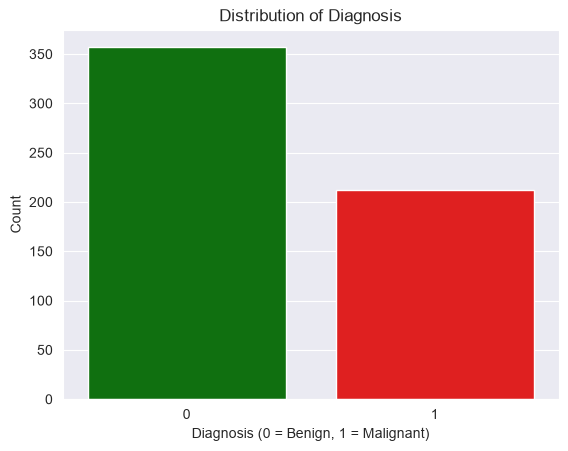

In [230]:
sns.countplot(
    data=df,
    x='diagnosis_M',
    hue='diagnosis_M',
    palette={0: 'green', 1: 'red'},
    legend=False
)

plt.title('Distribution of Diagnosis')
plt.xlabel('Diagnosis (0 = Benign, 1 = Malignant)')
plt.ylabel('Count')
plt.show()

### 4. Summary Statistics  - Numerical Features
#### Goal
 - Understand scale , central tendency and spread of all continous variables

In [231]:
num_cols = df.select_dtypes(include='number').columns

In [232]:
num_cols

Index(['id', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'diagnosis_M'],
      dtype='str')

In [233]:
# Check skewness
skew = df[num_cols].skew().sort_values(ascending=False)
print("Highly skewed features (|skew| > 1):")
print(skew[skew.abs() > 1])

Highly skewed features (|skew| > 1):
id                         6.473752
area_se                    5.447186
concavity_se               5.110463
fractal_dimension_se       3.923969
perimeter_se               3.443615
radius_se                  3.088612
smoothness_se              2.314450
symmetry_se                2.195133
compactness_se             1.902221
area_worst                 1.859373
fractal_dimension_worst    1.662579
texture_se                 1.646444
area_mean                  1.645732
compactness_worst          1.473555
concave points_se          1.444678
symmetry_worst             1.433928
concavity_mean             1.401180
fractal_dimension_mean     1.304489
compactness_mean           1.190123
concave points_mean        1.171180
concavity_worst            1.150237
perimeter_worst            1.128164
radius_worst               1.103115
dtype: float64


In [234]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,diagnosis_M
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.372583
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,0.000000
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


### 6. Numerical Features - Distribution by diagnosis
#### Goal
 - compare all key features by diagnosis

In [235]:
features = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst']

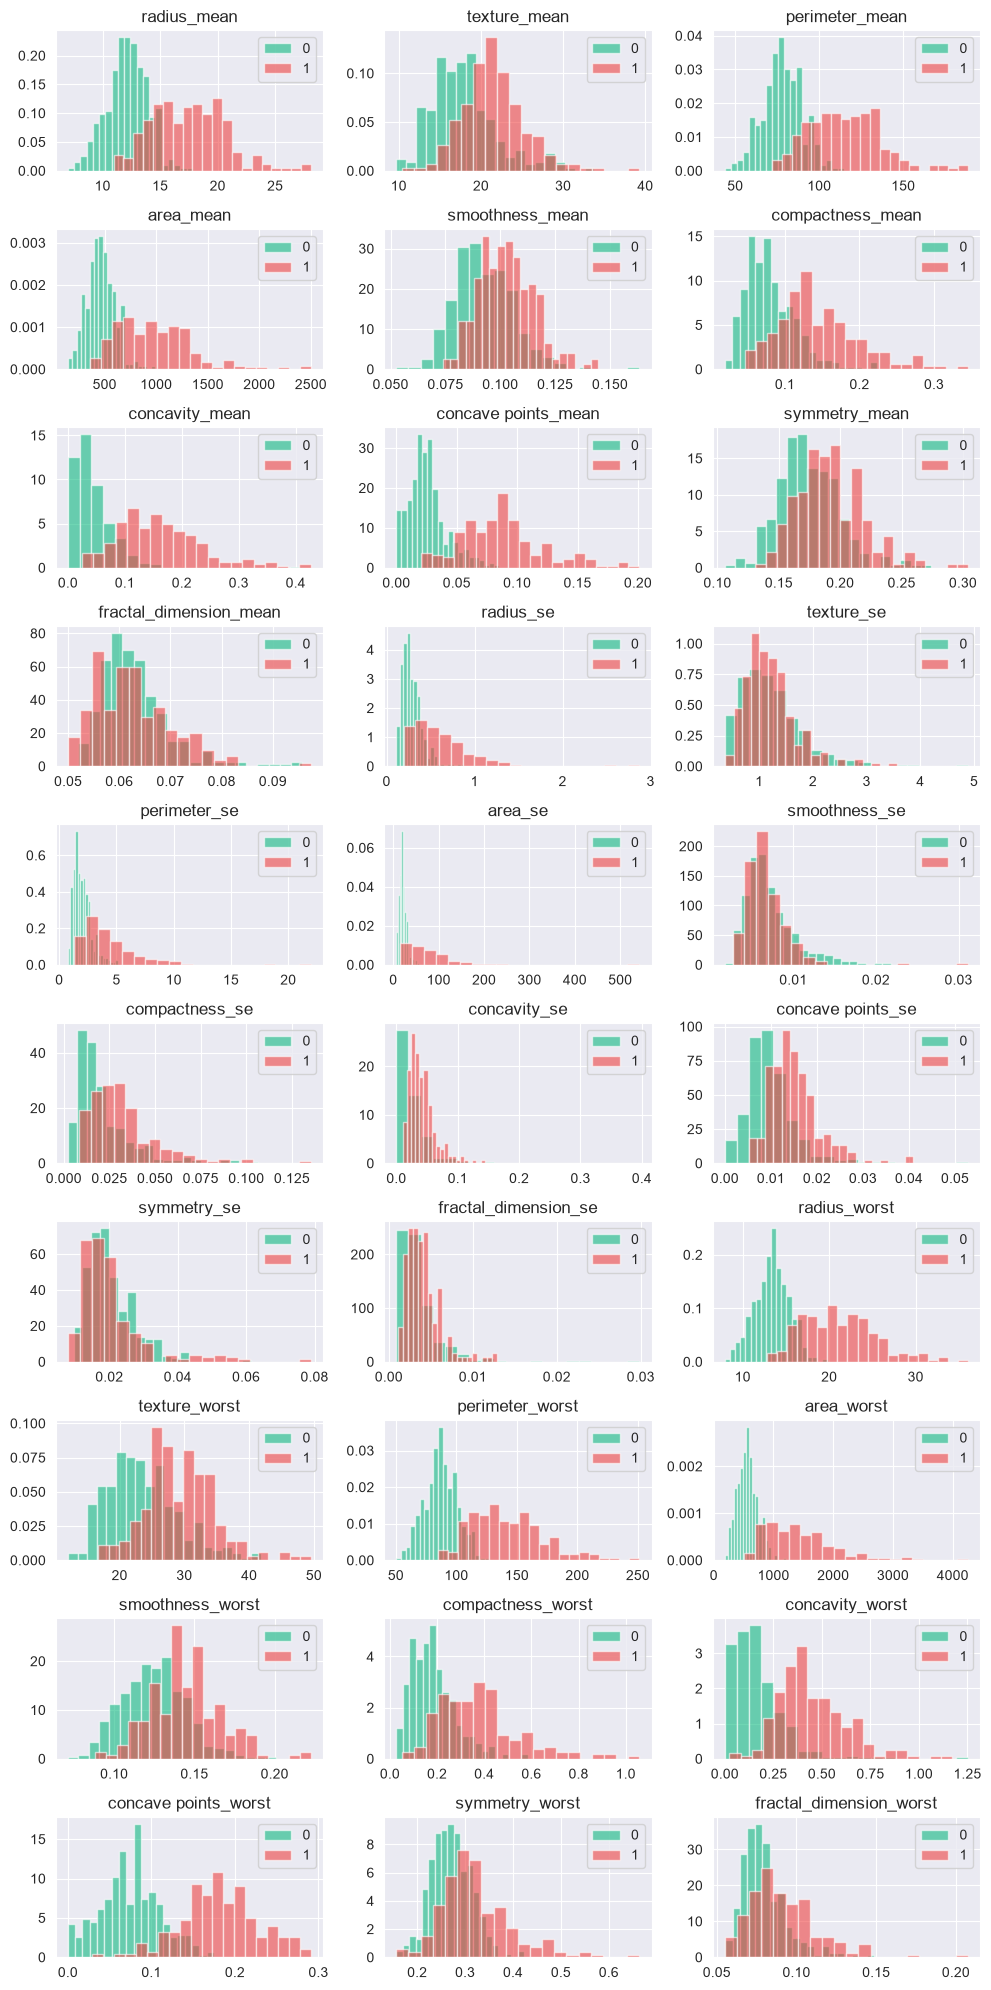

In [236]:
fig, axes = plt.subplots(10,3, figsize=(10,20))
for ax, col in zip(axes.flat, features):
    for label, color in [(0,'#10B981'), (1,'#EF4444')]:
        ax.hist(
            df[df['diagnosis_M'] == label][col],
            bins=20,
            alpha=0.6,
            label=label,
            color=color,
            density=True,
        )
        ax.legend()
        ax.set_title(col)
plt.tight_layout()


### 7.  Correlation Heatmap — Full Feature Matrix
Identify linear relationships between all features and spot multicollinearity

In [237]:
df_2 = df.drop(['id','diagnosis'],axis=1)

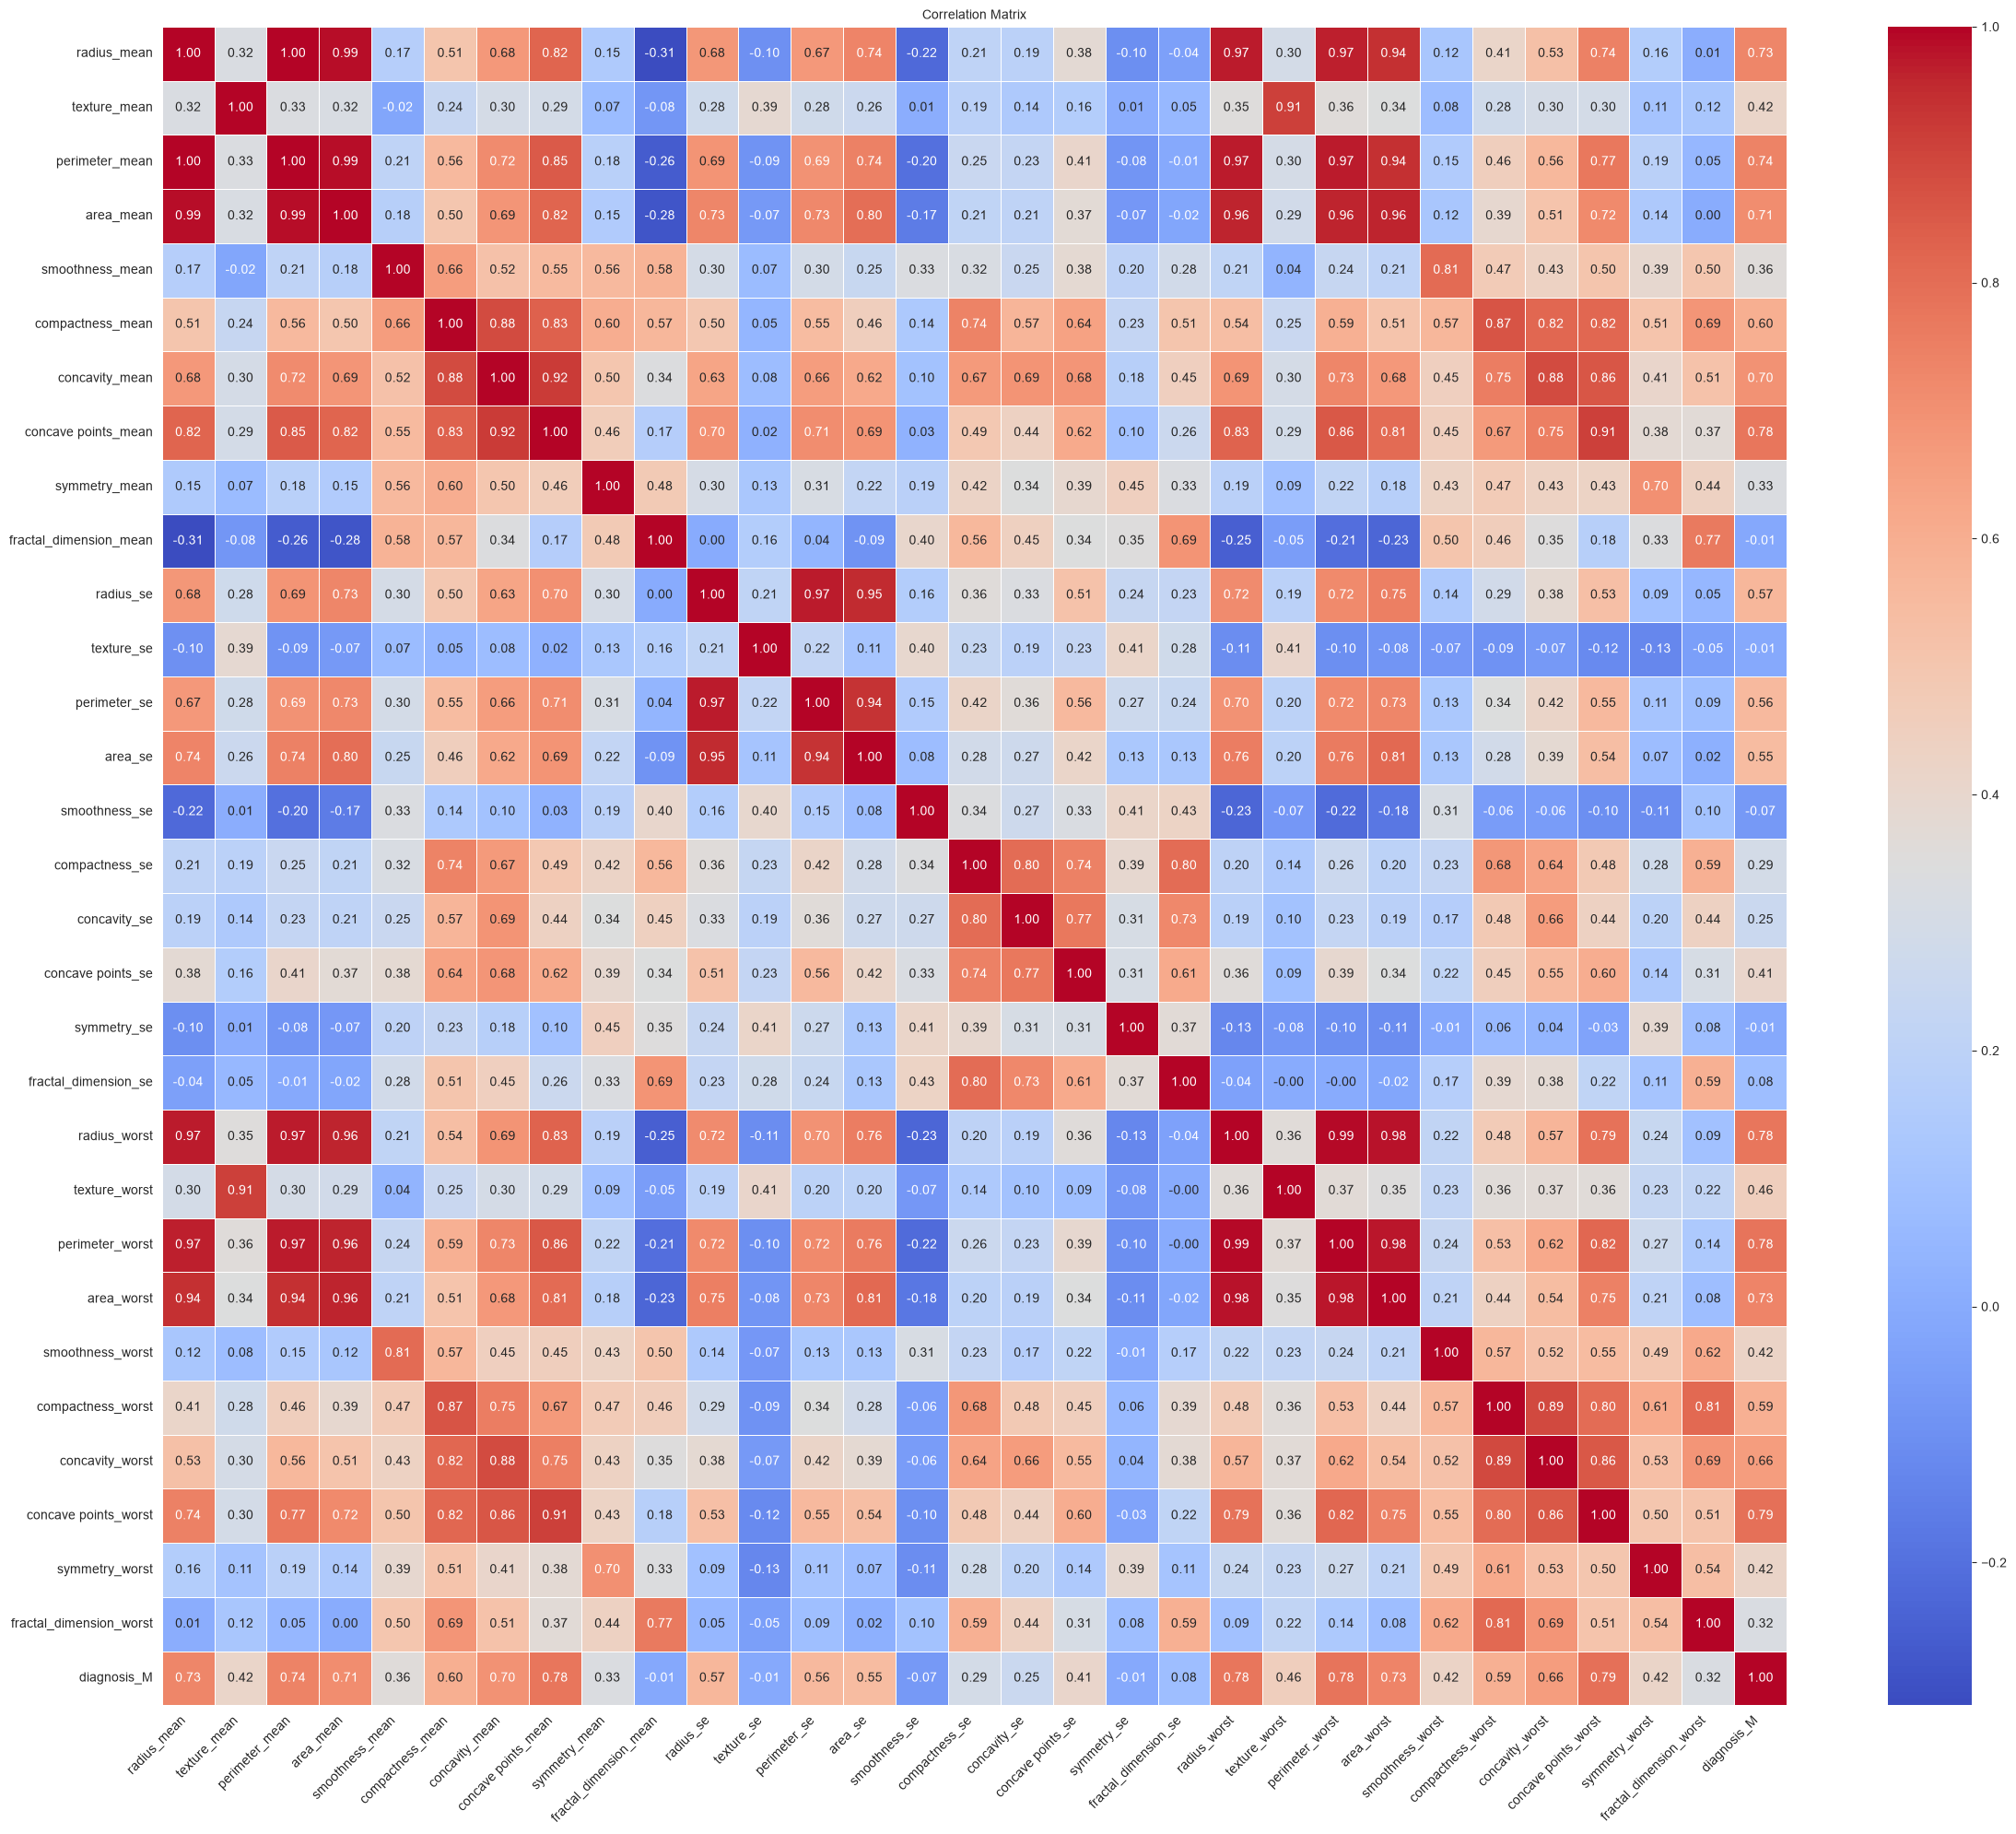

In [238]:

# corr = df_2.corr()
# sns.heatmap(corr, annot=True, fmt='.2f',
#             cmap='RdYlGn', center=0, linewidths=0.3)
plt.figure(figsize=(24, 20))
sns.heatmap(
    df_2.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix', fontsize=10)
plt.xticks(fontsize=10, rotation=45, ha='right')
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

<Axes: >

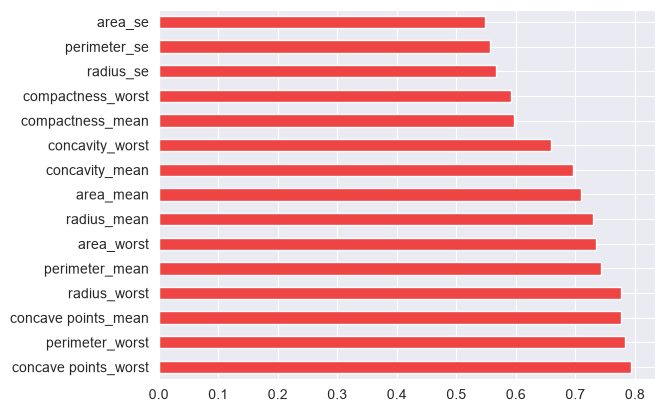

In [239]:
attr_corr = df_2.corr()['diagnosis_M'].drop('diagnosis_M')
attr_corr = attr_corr.sort_values(key=abs, ascending=False).head(15)
attr_corr.plot(kind='barh',
    color=['#EF4444' if v > 0 else '#10B981' for v in attr_corr])

# 2. Model Selection

In [240]:
## 1. Train/ test Split

In [241]:
X = df_2.drop(['diagnosis_M'],axis=1)
y = df_2['diagnosis_M']

In [242]:
x_train, x_test,y_train,y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

In [250]:
models = {
    'Logistic Regression': make_pipeline(
        StandardScaler(),
        LogisticRegression()
    ),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'SVM': make_pipeline(
        StandardScaler(),
        CalibratedClassifierCV(
        SVC(),
        ensemble=False,
        cv=3
    )
    ),
    'KNN': make_pipeline(
        StandardScaler(),
        KNeighborsClassifier()
    )
}

In [251]:
# Cross Validation setup
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [252]:
# Define evaluation metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0)
}

In [253]:
results = []

In [254]:
for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1-Score': scores['test_f1'].mean()
    })

In [255]:
# Display results, ranked by F1-score
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1-Score',
    ascending=False
).reset_index(drop=True)

print(results_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-Score
                SVM    0.9758     0.9773  0.9588    0.9670
Logistic Regression    0.9736     0.9771  0.9529    0.9640
      Random Forest    0.9648     0.9641  0.9412    0.9519
                KNN    0.9648     0.9875  0.9176    0.9510
      Decision Tree    0.9231     0.8996  0.8941    0.8962


In [256]:
# Cross-validation results for detecting malignant tumors
scoring_malignant = {
    'accuracy': 'accuracy',
    'precision': make_scorer(
        precision_score, pos_label=1, zero_division=0
    ),
    'recall': make_scorer(
        recall_score, pos_label=1, zero_division=0
    ),
    'f1': make_scorer(
        f1_score, pos_label=1, zero_division=0
    )
}

malignant_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring_malignant,
        n_jobs=-1
    )

    malignant_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Malignant Precision': scores['test_precision'].mean(),
        'Malignant Recall': scores['test_recall'].mean(),
        'Malignant F1': scores['test_f1'].mean()
    })

malignant_df = pd.DataFrame(malignant_results)

malignant_df = malignant_df.sort_values(
    by='Malignant Recall',
    ascending=False
).reset_index(drop=True)

print(malignant_df.round(4).to_string(index=False))

              Model  Accuracy  Malignant Precision  Malignant Recall  Malignant F1
                SVM    0.9758               0.9773            0.9588        0.9670
Logistic Regression    0.9736               0.9771            0.9529        0.9640
      Random Forest    0.9648               0.9641            0.9412        0.9519
                KNN    0.9648               0.9875            0.9176        0.9510
      Decision Tree    0.9231               0.8996            0.8941        0.8962


In [257]:
# Select based on malignant recall
best_model_name = malignant_df.loc[0].Model
best_model = models[best_model_name]

In [258]:
## Train on all
best_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('calibratedclassifiercv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['radius_mean','texture_mean','perimeter_mean',...,'concave points_worst', 'symmetry_worst','fractal_dimension_worst']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [259]:
# predict test data
y_pred = best_model.predict(X_test)

In [260]:
print(f"Selected model: {best_model_name}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, pos_label=0, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, pos_label=0, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, pos_label=0, zero_division=0):.4f}")

Selected model: SVM
Accuracy:  0.9649
Precision: 0.9722
Recall:    0.9722
F1-score:  0.9722


In [261]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[1, 0]))


Confusion Matrix:
[[40  2]
 [ 2 70]]


In [262]:
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Malignant', 'Benign'],
    zero_division=0
))


Classification Report:
              precision    recall  f1-score   support

   Malignant       0.97      0.97      0.97        72
      Benign       0.95      0.95      0.95        42

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



In [263]:
## Hyper parameter tuning for all 5-models

In [264]:
# Malignant = 1, so recall measures malignant detection
scoring = {
    'recall': make_scorer(
        recall_score, pos_label=1, zero_division=0
    ),
    'precision': make_scorer(
        precision_score, pos_label=1, zero_division=0
    ),
    'f1': make_scorer(
        f1_score, pos_label=1, zero_division=0
    ),
    'accuracy': 'accuracy'
}

In [267]:
# Hyperparameter combinations to test for each model
param_grids = {
    'Logistic Regression': {
        'logisticregression__C': [0.01, 0.1, 1, 10, 100],
        'logisticregression__class_weight': [None, 'balanced']
    },

    'Random Forest': {
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 5, 10, 20],
        'min_samples_split': [2, 5, 10],
        'class_weight': [None, 'balanced']
    },

    'Decision Tree': {
        'max_depth': [None, 3, 5, 10, 20],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'class_weight': [None, 'balanced']
    },

    'SVM': {
        'svc__C': [0.01, 0.1, 1, 10, 100],
        'svc__kernel': ['linear', 'rbf'],
        'svc__gamma': ['scale', 0.001, 0.01, 0.1, 1],
        'svc__class_weight': [None, 'balanced']
    },

    'KNN': {
        'kneighborsclassifier__n_neighbors': [3, 5, 7, 9, 11, 15],
        'kneighborsclassifier__weights': ['uniform', 'distance'],
        'kneighborsclassifier__p': [1, 2]
    }
}

In [268]:
# Tune each model using training data only
tuning_results = []
best_estimators = {}

for name, model in models.items():

    search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring=scoring,
        refit='recall',
        cv=cv,
        n_jobs=-1,
        return_train_score=False
    )

    search.fit(X_train, y_train)

    best_estimators[name] = search.best_estimator_

    tuning_results.append({
        'Model': name,
        'CV Recall': search.cv_results_[
            'mean_test_recall'
        ][search.best_index_],
        'CV Precision': search.cv_results_[
            'mean_test_precision'
        ][search.best_index_],
        'CV F1': search.cv_results_[
            'mean_test_f1'
        ][search.best_index_],
        'CV Accuracy': search.cv_results_[
            'mean_test_accuracy'
        ][search.best_index_],
        'Best Parameters': search.best_params_
    })

In [269]:
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by='CV Recall',
    ascending=False
).reset_index(drop=True)

print(tuning_df.round(4).to_string(index=False))

              Model  CV Recall  CV Precision  CV F1  CV Accuracy                                                                                                                                                                                            Best Parameters
                SVM     0.9765        0.5825 0.7296       0.7297 {'calibratedclassifiercv__estimator__C': 0.01, 'calibratedclassifiercv__estimator__class_weight': None, 'calibratedclassifiercv__estimator__gamma': 1, 'calibratedclassifiercv__estimator__kernel': 'rbf'}
Logistic Regression     0.9588        0.9650 0.9616       0.9714                                                                                                                               {'logisticregression__C': 1, 'logisticregression__class_weight': 'balanced'}
      Random Forest     0.9529        0.9477 0.9500       0.9626                                                                                                               {'class_weight': 'bal

In [270]:
best_name = tuning_df.loc[0, 'Model']
best_model = best_estimators[best_name]

print("Selected model:", best_name)
print("Cross-validated malignant recall:",
      round(tuning_df.loc[0, 'CV Recall'], 4))

print("\nBest parameters:")
print(tuning_df.loc[0, 'Best Parameters'])

Selected model: SVM
Cross-validated malignant recall: 0.9765

Best parameters:
{'calibratedclassifiercv__estimator__C': 0.01, 'calibratedclassifiercv__estimator__class_weight': None, 'calibratedclassifiercv__estimator__gamma': 1, 'calibratedclassifiercv__estimator__kernel': 'rbf'}


In [271]:
y_pred = best_model.predict(X_test)

print("Selected model:", best_name)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, pos_label=1, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, pos_label=1, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, pos_label=1, zero_division=0):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[1, 0]))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[1, 0],
    target_names=['Malignant', 'Benign'],
    zero_division=0
))

Selected model: SVM
Accuracy:  0.7193
Precision: 0.5694
Recall:    0.9762
F1-score:  0.7193

Confusion Matrix:
[[41  1]
 [31 41]]

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.57      0.98      0.72        42
      Benign       0.98      0.57      0.72        72

    accuracy                           0.72       114
   macro avg       0.77      0.77      0.72       114
weighted avg       0.83      0.72      0.72       114



In [273]:
# Use the calibrated SVM's predicted probabilities
y_prob = best_model.predict_proba(X_test)[:, 1]

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7,0.8]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Recall:", round(
        recall_score(y_test, y_pred_threshold), 3
    ))
    print("Precision:", round(
        precision_score(y_test, y_pred_threshold, zero_division=0), 3
    ))
    print("F1:", round(
        f1_score(y_test, y_pred_threshold, zero_division=0), 3
    ))
    print(confusion_matrix(
        y_test, y_pred_threshold, labels=[1, 0]
    ))


Threshold: 0.3
Recall: 0.976
Precision: 0.554
F1: 0.707
[[41  1]
 [33 39]]

Threshold: 0.4
Recall: 0.976
Precision: 0.562
F1: 0.713
[[41  1]
 [32 40]]

Threshold: 0.5
Recall: 0.976
Precision: 0.569
F1: 0.719
[[41  1]
 [31 41]]

Threshold: 0.6
Recall: 0.976
Precision: 0.569
F1: 0.719
[[41  1]
 [31 41]]

Threshold: 0.7
Recall: 0.976
Precision: 0.612
F1: 0.752
[[41  1]
 [26 46]]

Threshold: 0.8
Recall: 0.952
Precision: 0.635
F1: 0.762
[[40  2]
 [23 49]]
